In [1]:
import sys
sys.path.append('..')
import logging
logging.basicConfig(level=logging.WARN)

In [2]:
from qunoc.element.benchmark import *

vqe_program = VQE(5)
print(f"VQE program: {vqe_program}")
qft_program = QFT(5)
print(f"QFT program: {qft_program}")
qaoa_program = QAOA(5)
print(f"QAOA program: {qaoa_program}")
bv_program = BV(5)
print(f"BV program: {bv_program}")

VQE program: Control_0_1, Control_0_2, Control_0_3, Control_0_4, Control_1_2, Control_1_3, Control_1_4, Control_2_3, Control_2_4, Control_3_4
QFT program: Control_1_0, Control_2_0, Control_3_0, Control_2_1, Control_4_0, Control_3_1, Control_4_1, Control_3_2, Control_4_2, Control_4_3
QAOA program: Control_1_3, Control_1_4, Control_0_3, Control_0_1, Control_2_4
BV program: Control_0_1, Control_0_3


Initial score:  0.0006371872076446246
New action:  (ComputeModule_0_0_49_49, Grid, X, 7)
New score:  0.001000682166276891
New action:  (ComputeModule_8_32_14_38, Grid, Y, 1)
New score:  0.0010391008670096998
Package score:  0.0009270634851803853


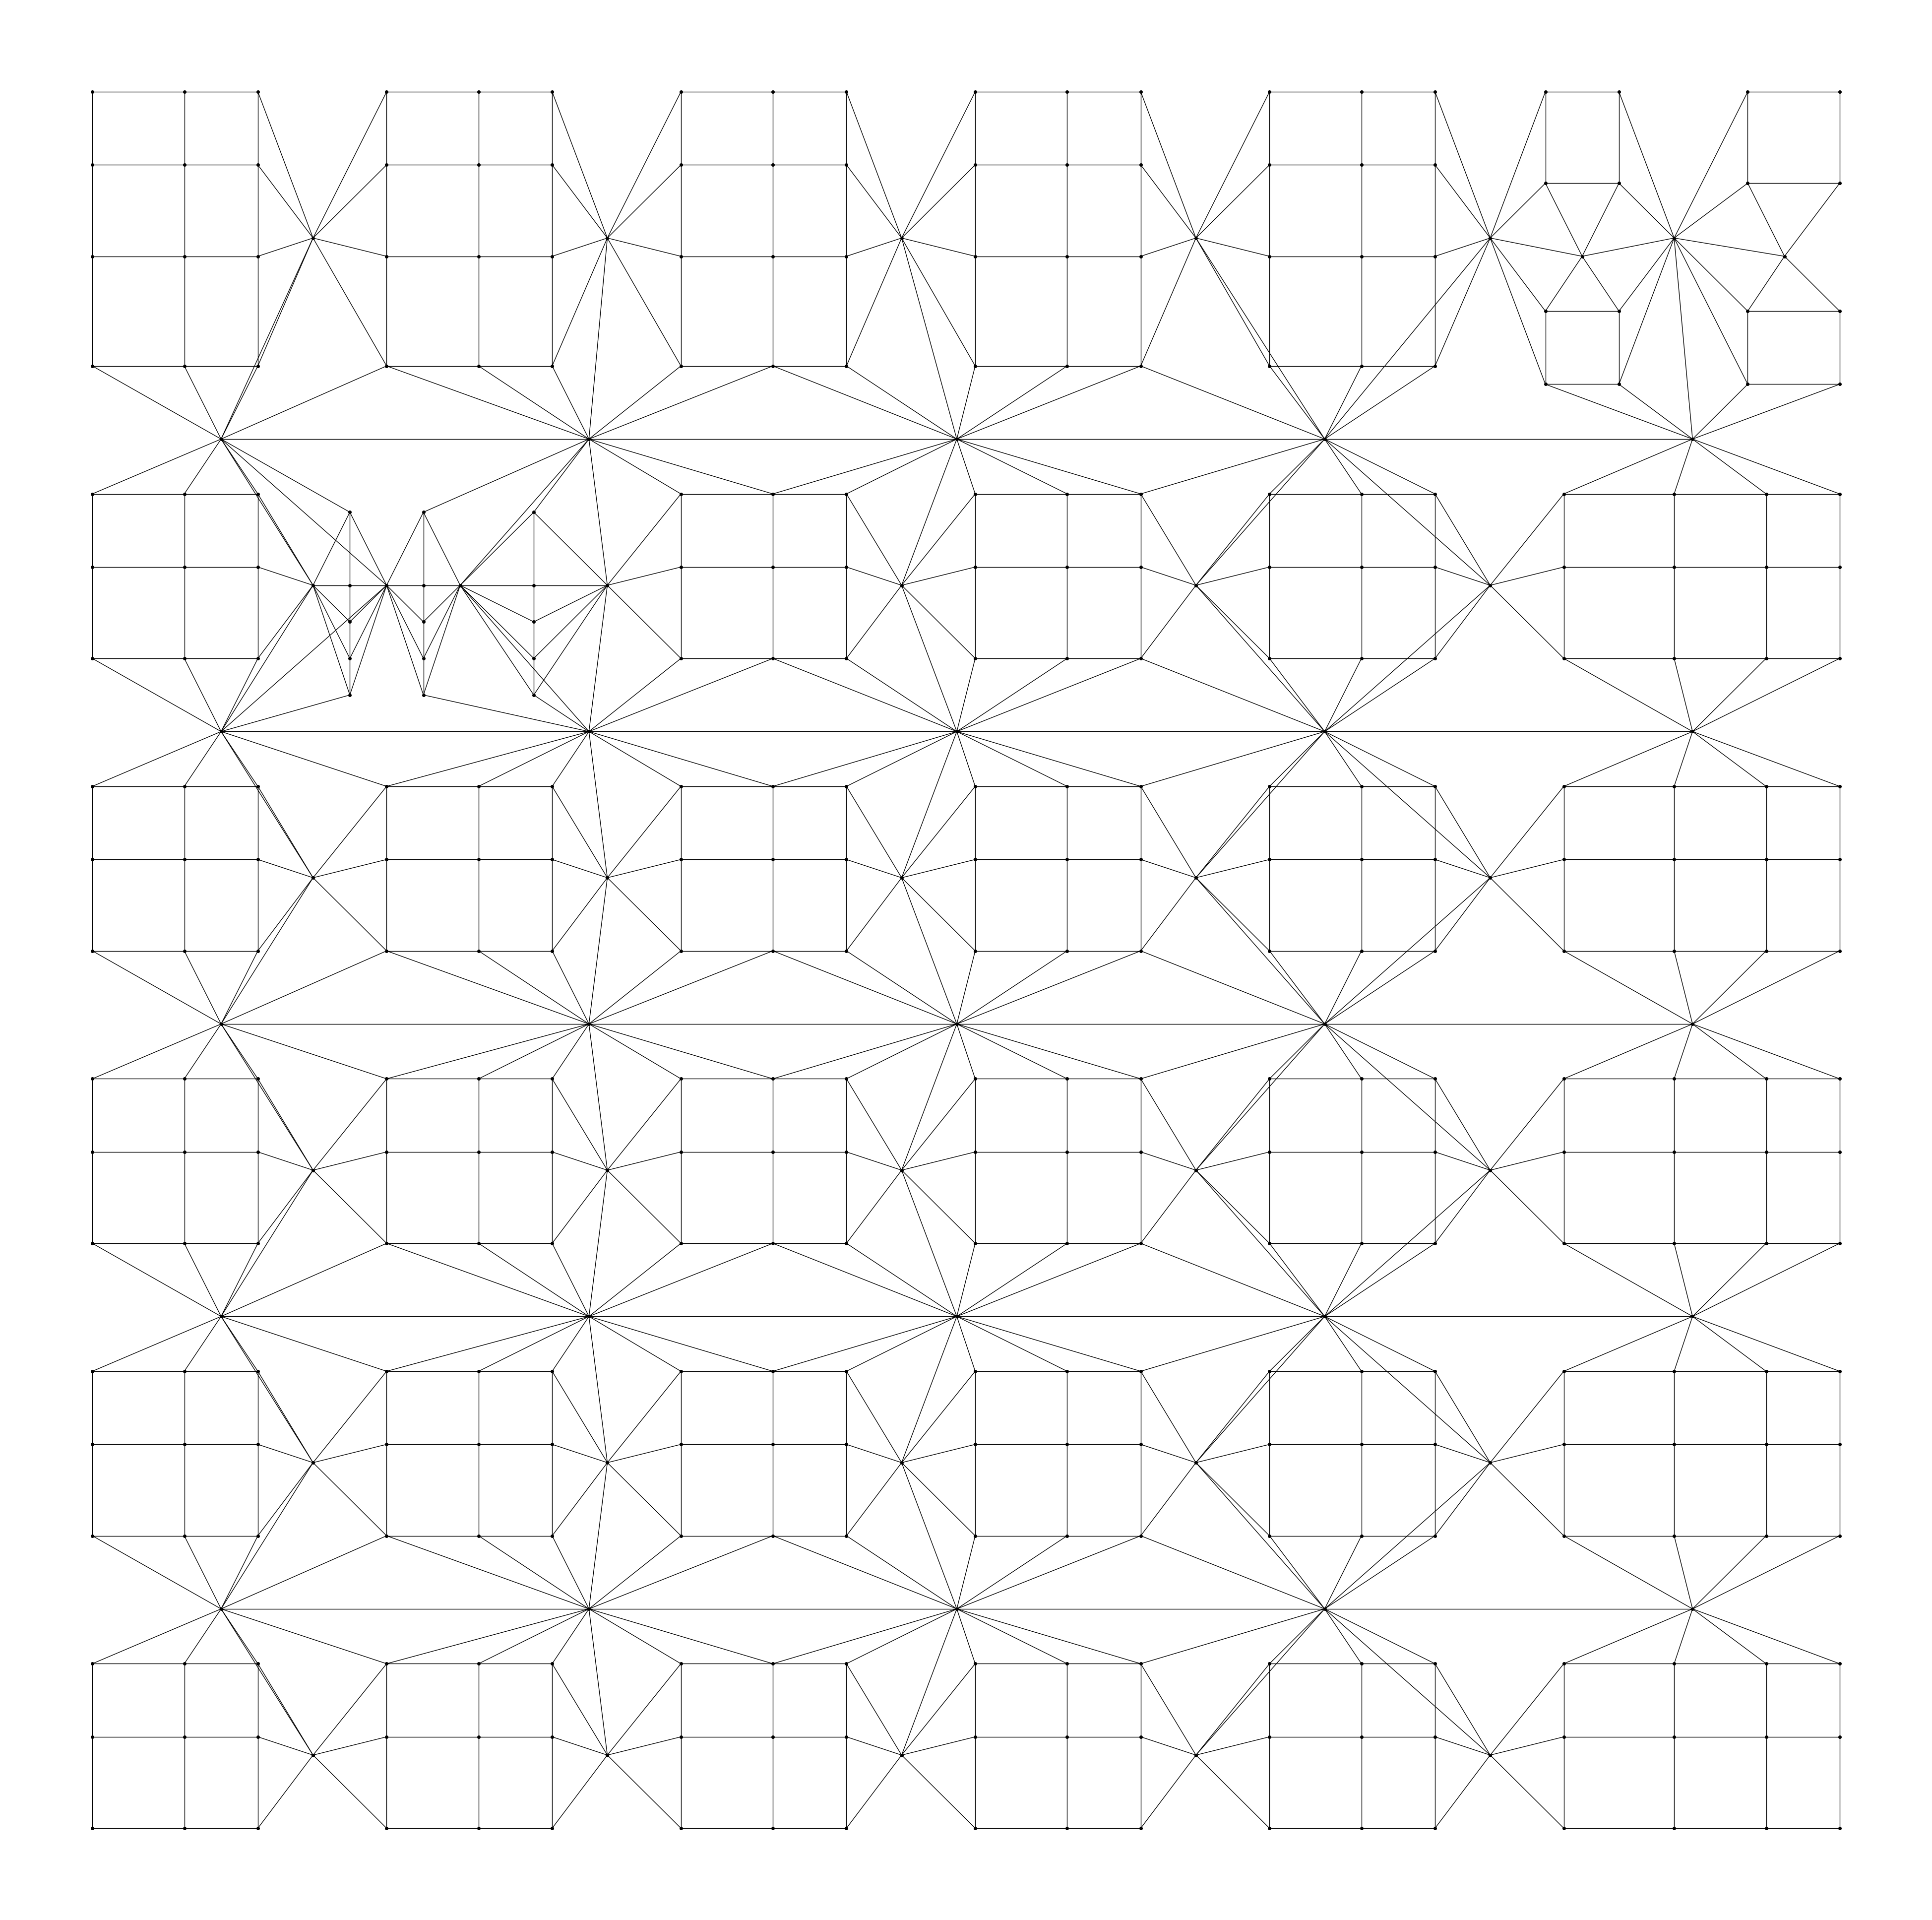

In [3]:
from qunoc.element.package import *

# package = Package(design_strategy="greedy")
fabricate_model = FabricateModel(10, 10)
package = Package((50, 50), fabricate_model, design_strategy="greedy")

print("Package score: ", package.estimate_efficiency())
package.draw_chiplets()

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Training agent...
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 393      |
|    ep_rew_mean     | -3.7e+10 |
| time/              |          |
|    fps             | 8        |
|    iterations      | 1        |
|    time_elapsed    | 229      |
|    total_timesteps | 2048     |
---------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 394           |
|    ep_rew_mean          | -3.7e+10      |
| time/                   |               |
|    fps                  | 8             |
|    iterations           | 2             |
|    time_elapsed         | 500           |
|    total_timesteps      | 4096          |
| train/                  |               |
|    approx_kl            | 7.0052774e-05 |
|    clip_fraction        | 0             |
|    clip_range     

/Users/chutianyao/anaconda3/envs/qunoc/lib/python3.10/site-packages/stable_baselines3/common/save_util.py:284: UserWarning: Path 'result/layout/rl/example_20250417114819' does not exist. Will create it.
  warnings.warn(f"Path '{path.parent}' does not exist. Will create it.")


Designing layout...
Package score:  0.0004555274662349221


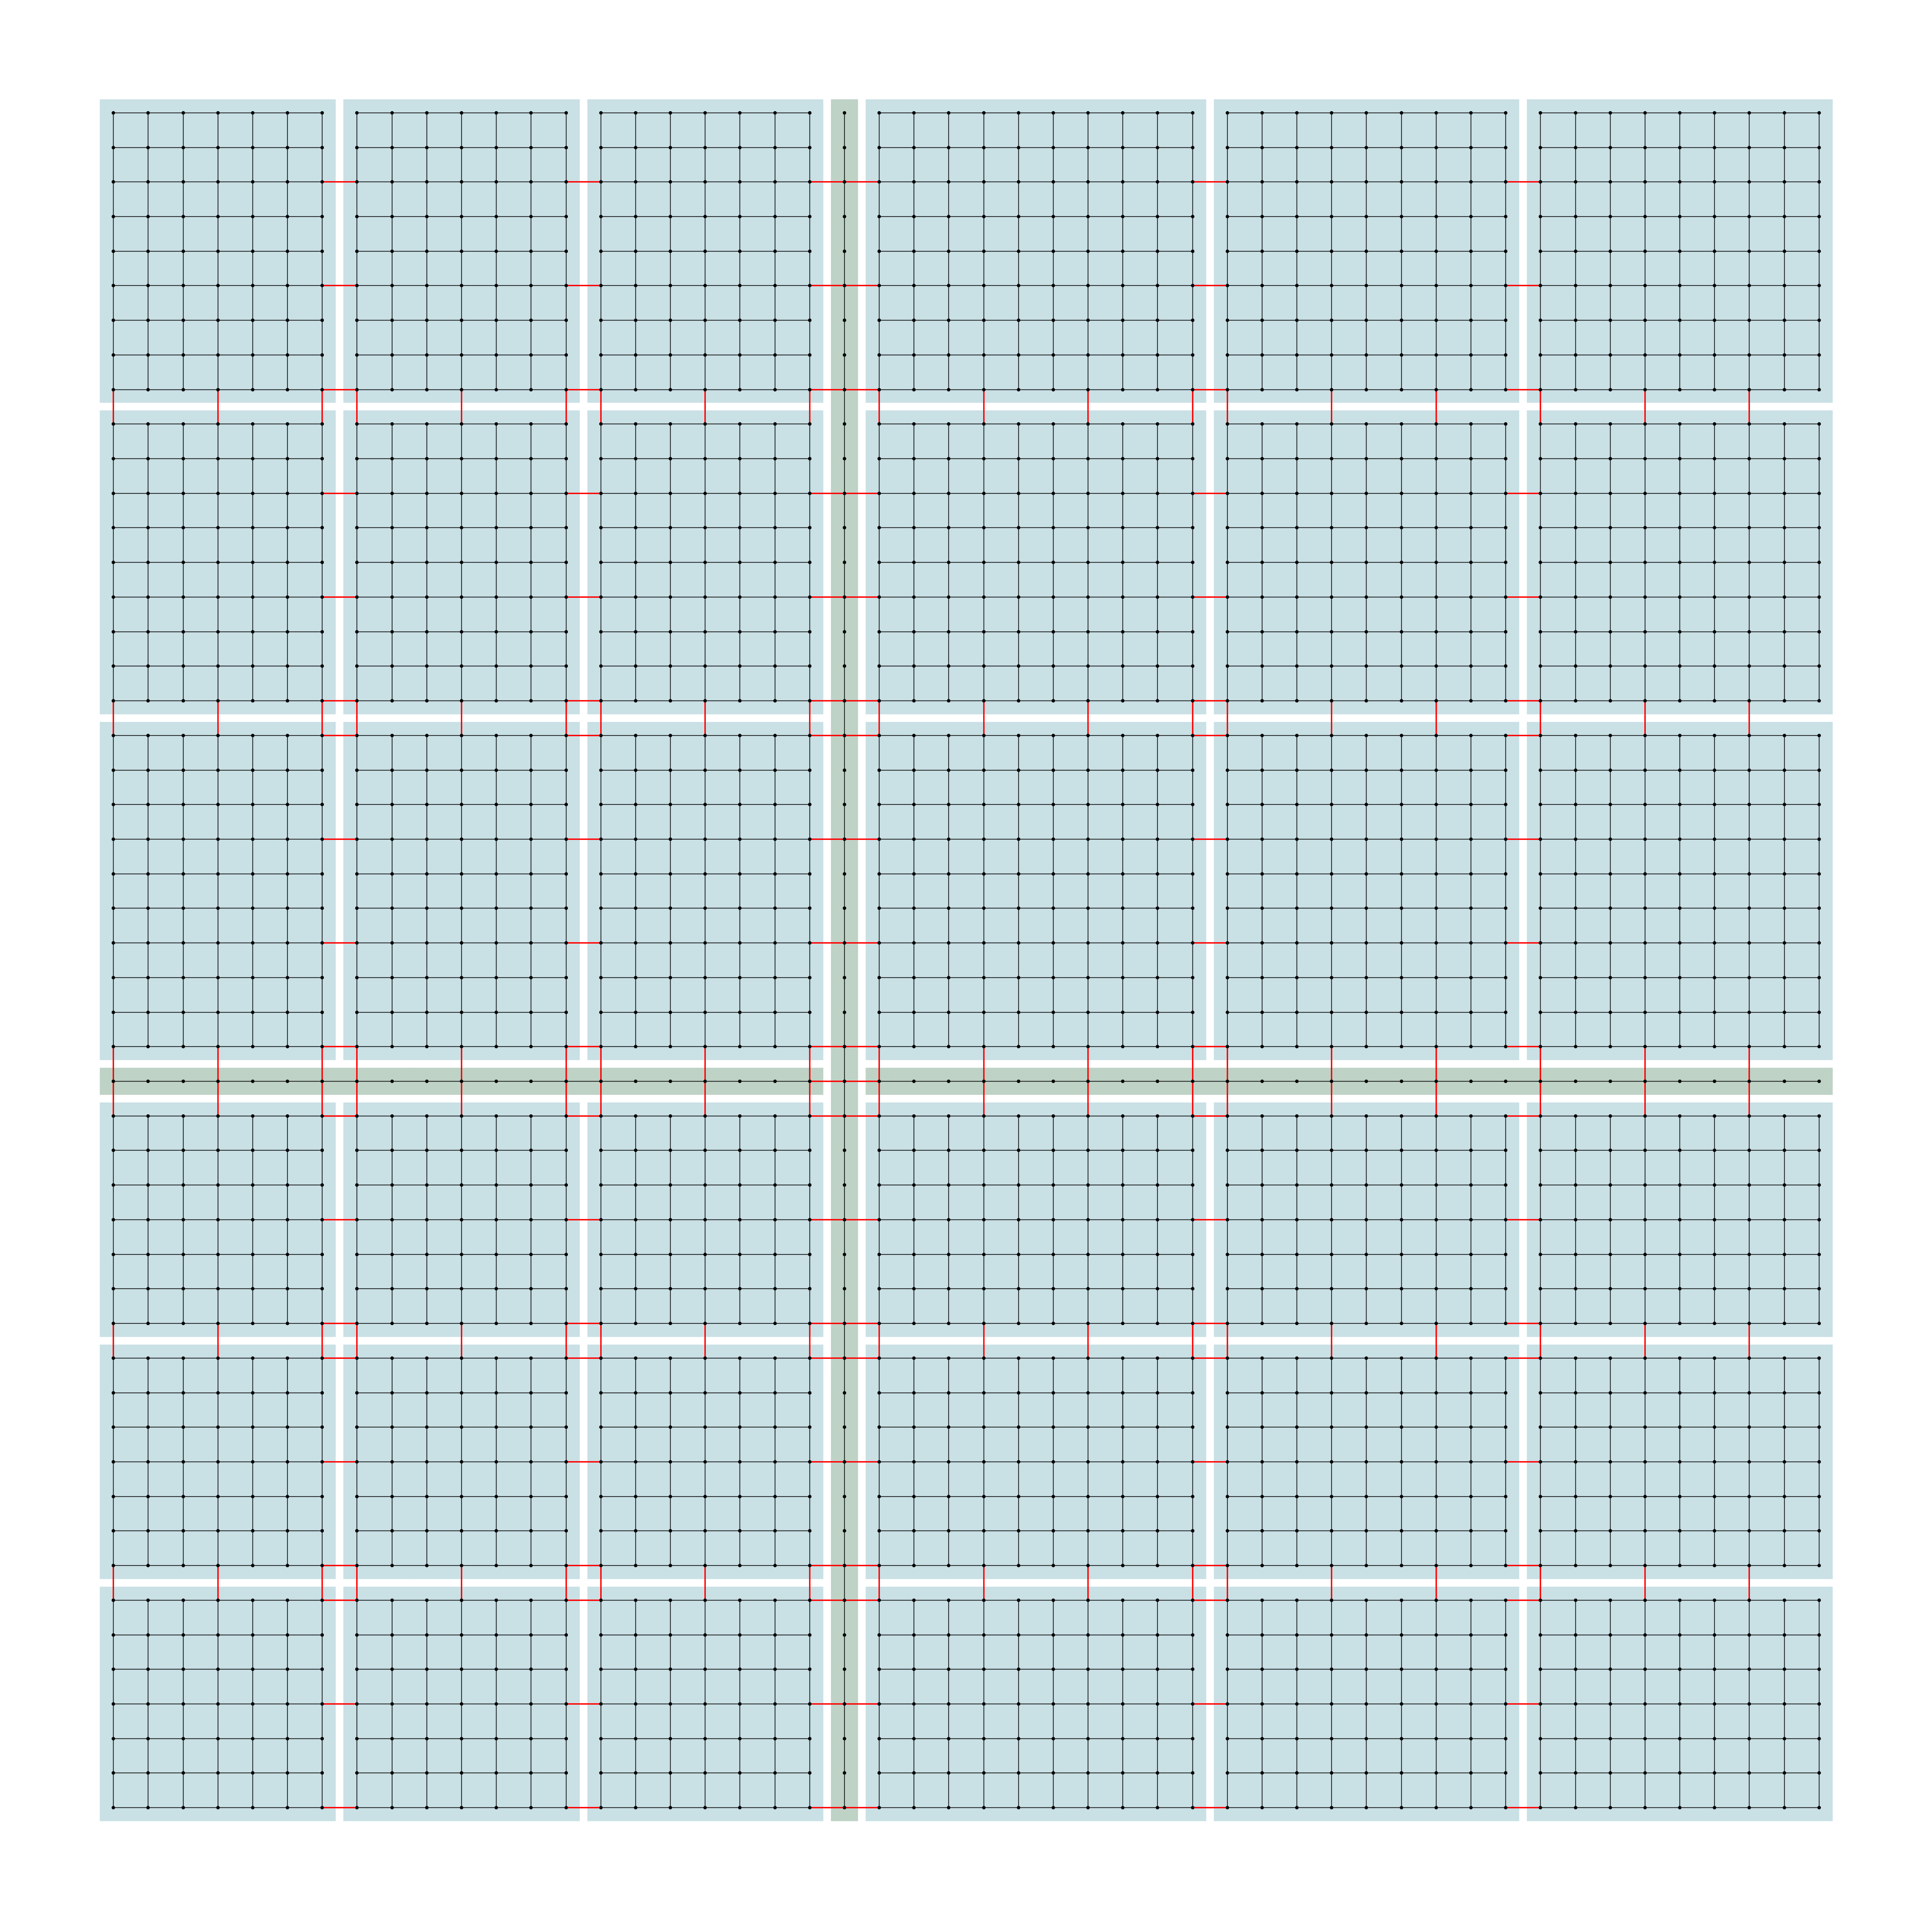

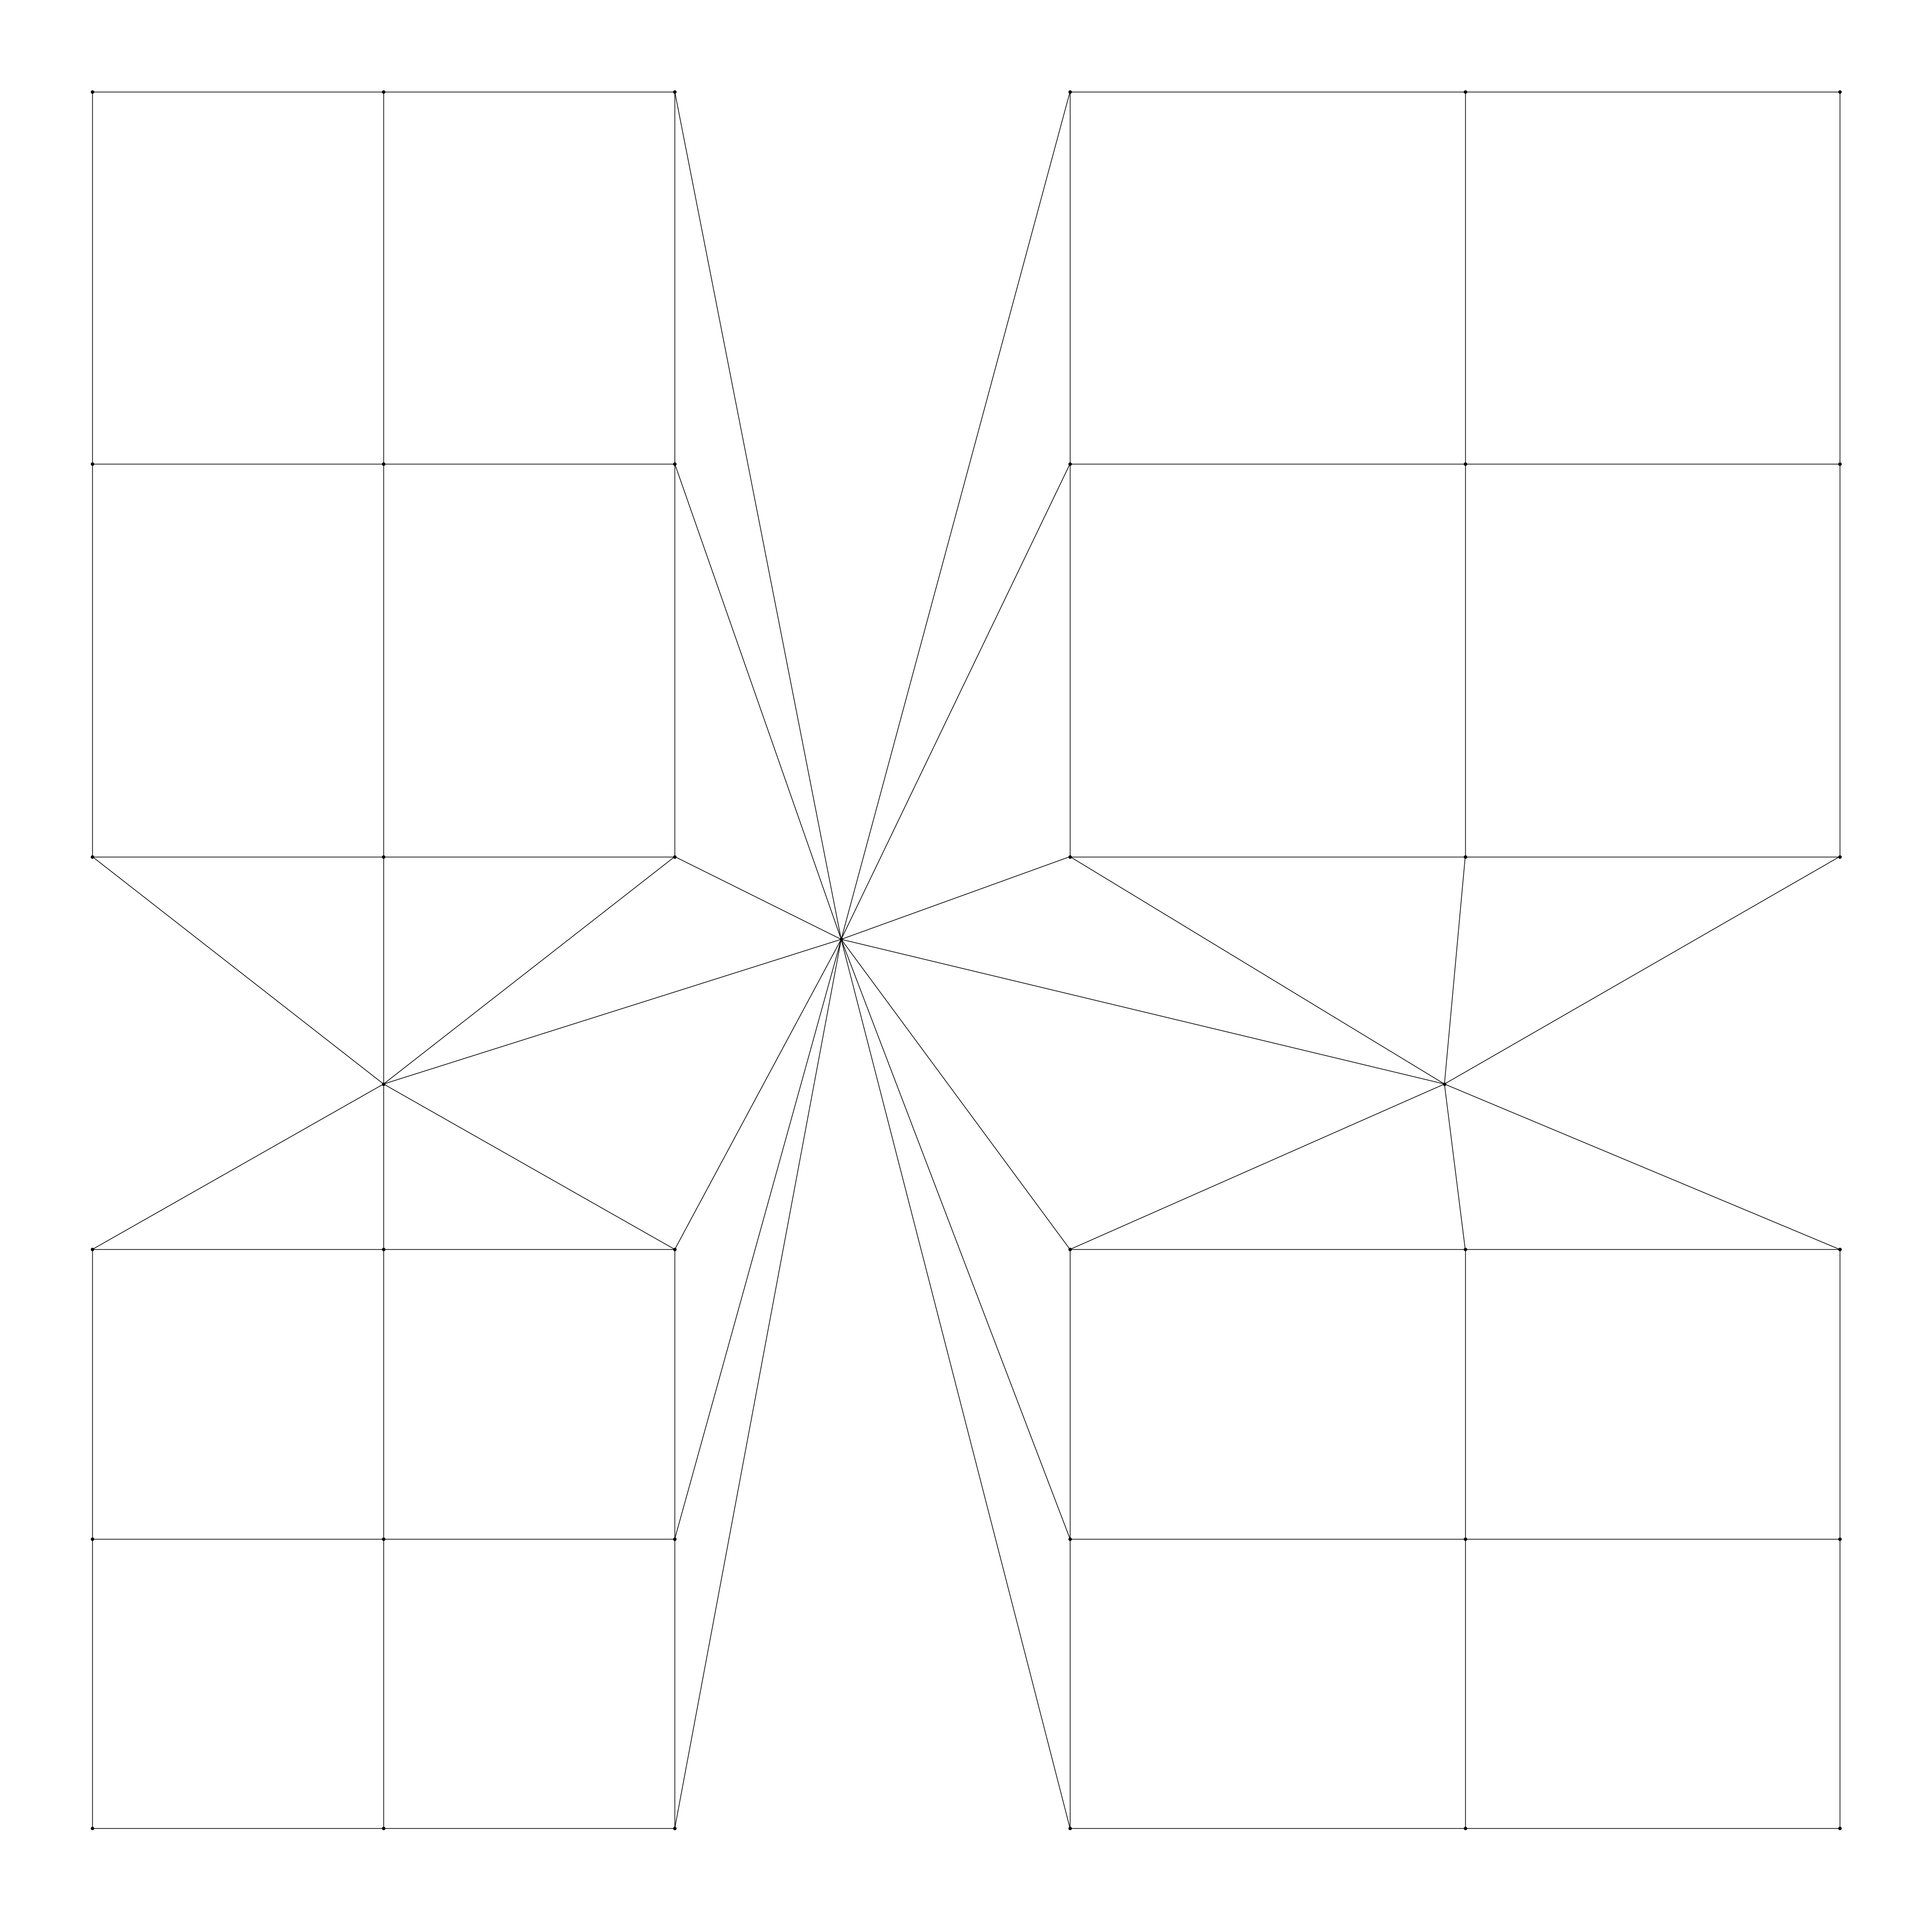

In [ ]:
import os
# from gymnasium.wrappers import Monitor

from qunoc.utils.utils import get_timestamp
from qunoc.layout.env import QuNoCEnv
from qunoc.layout.agent import LayoutAgent

env = QuNoCEnv()
# env = Monitor(env, "./logs")
agent = LayoutAgent(env)

agent.train()
model_dir = f"result/layout/rl/example_{get_timestamp()}/"
os.makedirs(model_dir, exist_ok=True)
agent.save(f"{model_dir}/layout_agent.pth")

package = agent.design()
print("Package score: ", package.estimate_efficiency())
package.draw_qubits(save_path=f"{model_dir}/qubit_topology.png")
package.draw_chiplets(save_path=f"{model_dir}/chiplet_topology.png")